In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

print("Libraries imported successfully!")

Libraries imported successfully!


In [24]:
DATA_URL="bodyPerformance.csv"
raw_data= pd.read_csv(DATA_URL)
raw_data.head()

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [25]:
#creating copy of original data
df1=raw_data.copy()

# Cleaning column names
df1.columns = df1.columns.astype(str).str.strip()
print("Columns:", df1.columns.tolist())

# Checking missing values
print("\nMissing values:")
display(df1.isnull().sum())

# Checking and removing duplicate rows
print("\nDuplicate rows:", df1.duplicated().sum())
df1.drop_duplicates(inplace=True)

# Displaying dataset after cleaning
print("\nShape after cleaning:", df1.shape)
display(df1.head())

# Dataset information after cleaning
print("\nDataset information after cleaning:")
df1.info()

# Statistical summary after cleaning
print("\nStatistical summary after cleaning:")
display(df1.describe())

Columns: ['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm', 'class']

Missing values:


age                        0
gender                     0
height_cm                  0
weight_kg                  0
body fat_%                 0
diastolic                  0
systolic                   0
gripForce                  0
sit and bend forward_cm    0
sit-ups counts             0
broad jump_cm              0
class                      0
dtype: int64


Duplicate rows: 1

Shape after cleaning: (13392, 12)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B



Dataset information after cleaning:
<class 'pandas.DataFrame'>
Index: 13392 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13392 non-null  float64
 1   gender                   13392 non-null  str    
 2   height_cm                13392 non-null  float64
 3   weight_kg                13392 non-null  float64
 4   body fat_%               13392 non-null  float64
 5   diastolic                13392 non-null  float64
 6   systolic                 13392 non-null  float64
 7   gripForce                13392 non-null  float64
 8   sit and bend forward_cm  13392 non-null  float64
 9   sit-ups counts           13392 non-null  float64
 10  broad jump_cm            13392 non-null  float64
 11  class                    13392 non-null  str    
dtypes: float64(10), str(2)
memory usage: 1.3 MB

Statistical summary after cleaning:


,age,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm
count,13392.000000,13392.000000,13392.000000,13392.000000,13392.000000,13392.000000,13392.000000,13392.000000,13392.000000,13392.000000
mean,36.775836,168.560671,67.448686,23.239608,78.797499,130.238120,36.964569,15.208933,39.770385,190.131355
std,13.625886,8.426305,11.949061,7.256829,10.742165,14.709536,10.624959,8.456904,14.276902,39.868988
min,21.000000,125.000000,26.300000,3.000000,0.000000,0.000000,0.000000,-25.000000,0.000000,0.000000
25%,25.000000,162.400000,58.200000,18.000000,71.000000,120.000000,27.500000,10.900000,30.000000,162.000000
50%,32.000000,169.200000,67.400000,22.800000,79.000000,130.000000,37.900000,16.200000,41.000000,193.000000
75%,48.000000,174.800000,75.300000,28.000000,86.000000,141.000000,45.200000,20.700000,50.000000,221.000000
max,64.000000,193.800000,138.100000,78.400000,156.200000,201.000000,70.500000,213.000000,80.000000,303.000000


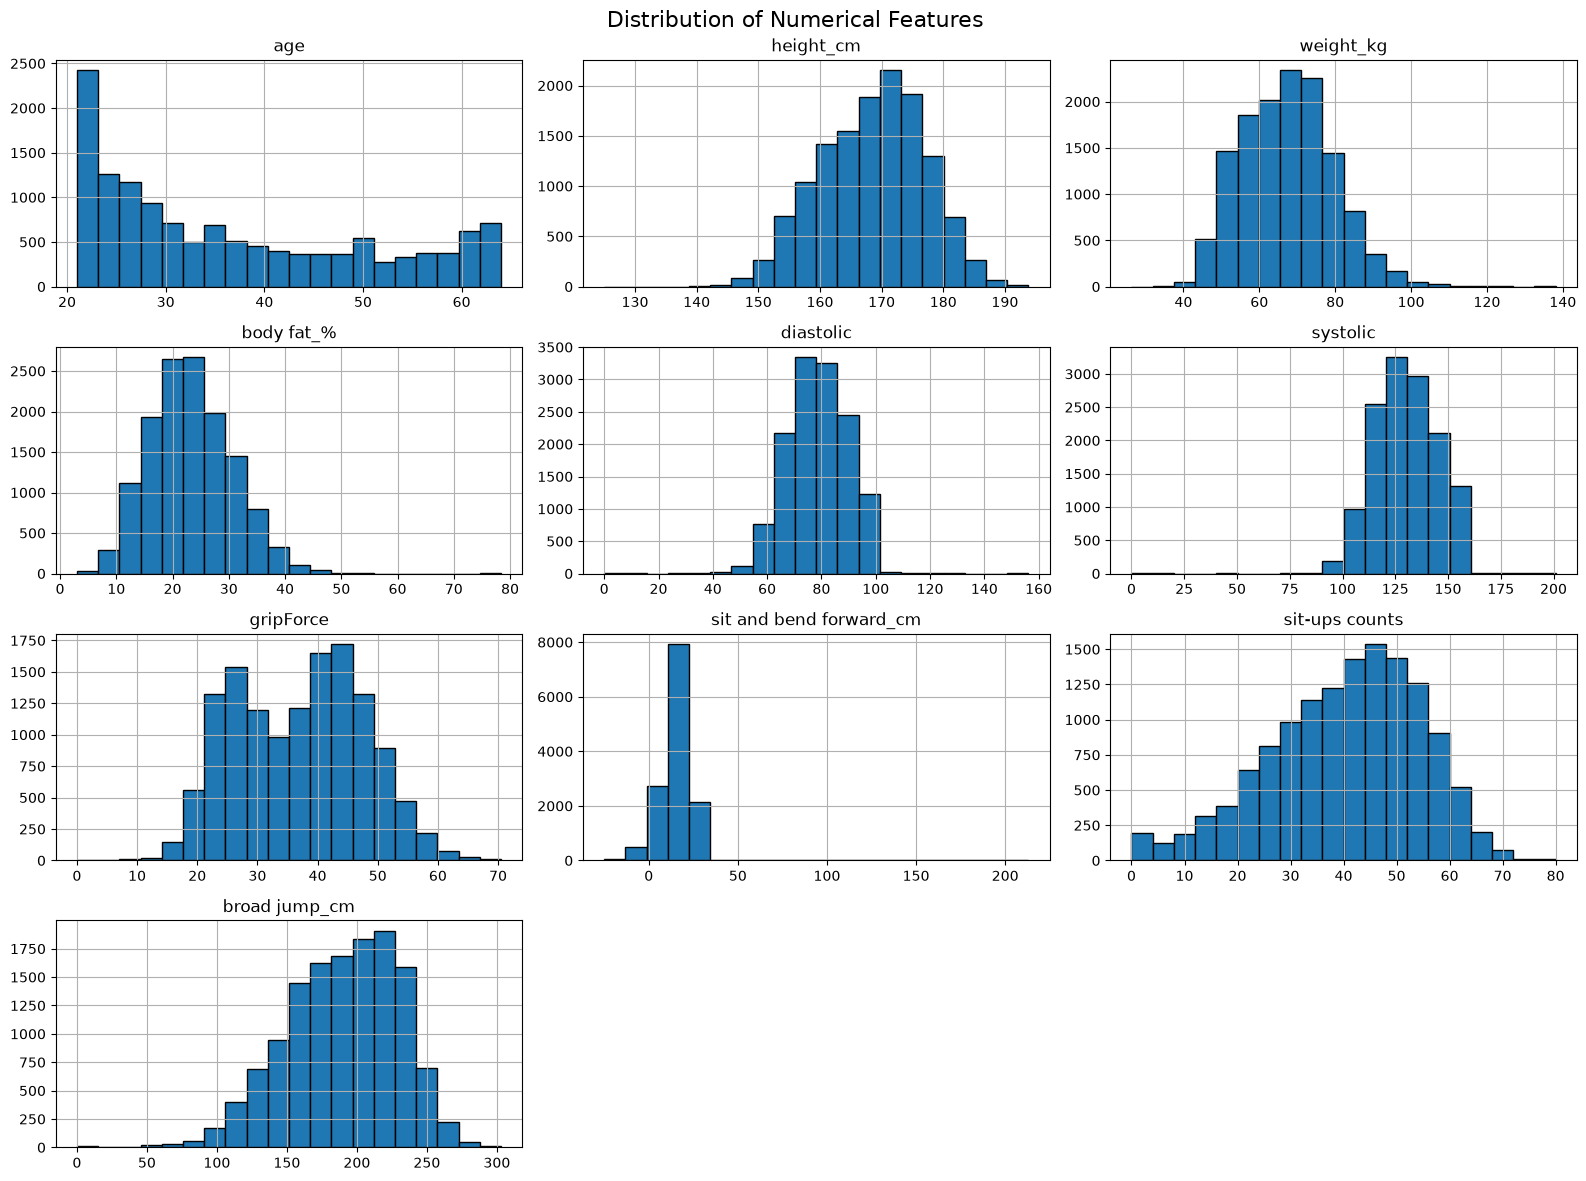

In [26]:
# Selecting numerical columns
numeric_cols = df1.select_dtypes(include='number').columns

# Plotting distributions
df1[numeric_cols].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

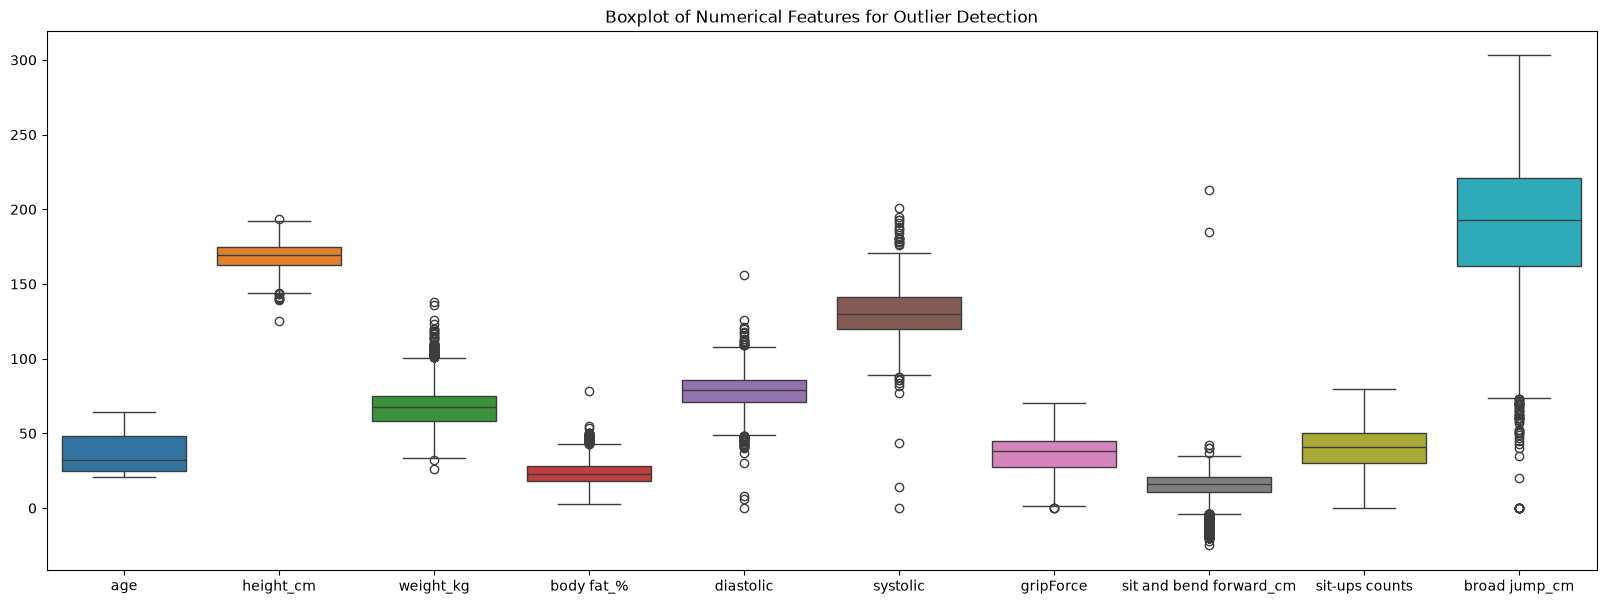

In [27]:
plt.figure(figsize=(20,7))
sns.boxplot(data=df1)
plt.title("Boxplot of Numerical Features for Outlier Detection")
plt.show()

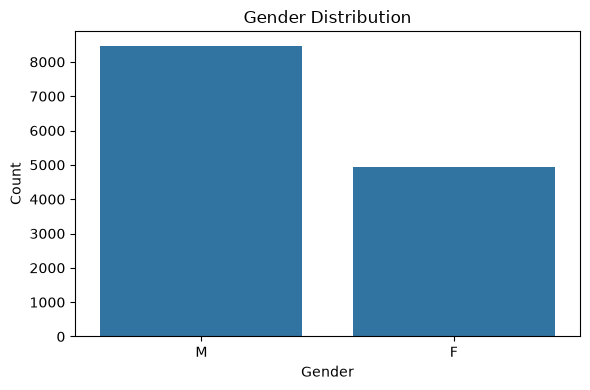

In [28]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df1, x='gender')

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

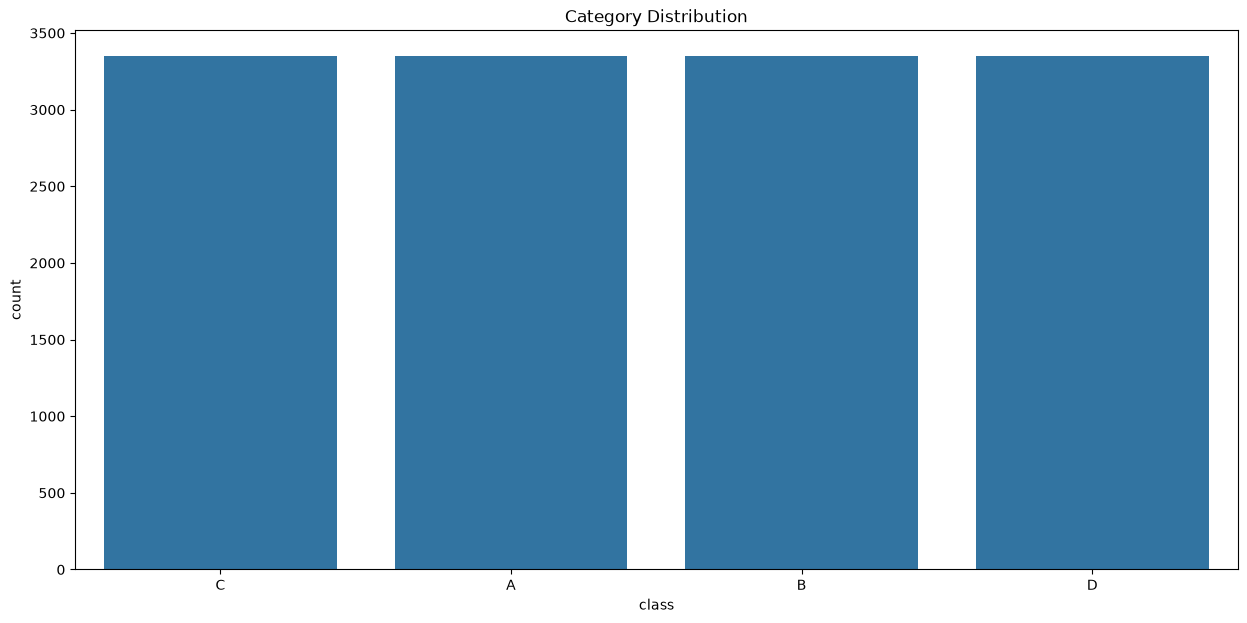

In [29]:
plt.figure(figsize=(15,7))
sns.countplot(x='class',data=df1)
plt.title("Category Distribution")
plt.show()

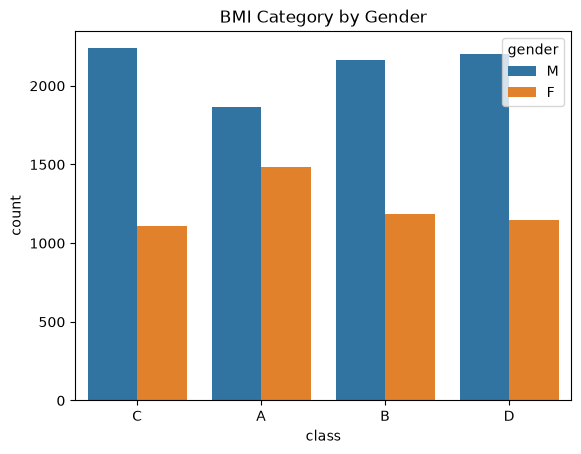

In [30]:
sns.countplot(x='class', hue='gender', data=df1)
plt.title("BMI Category by Gender")
plt.show()

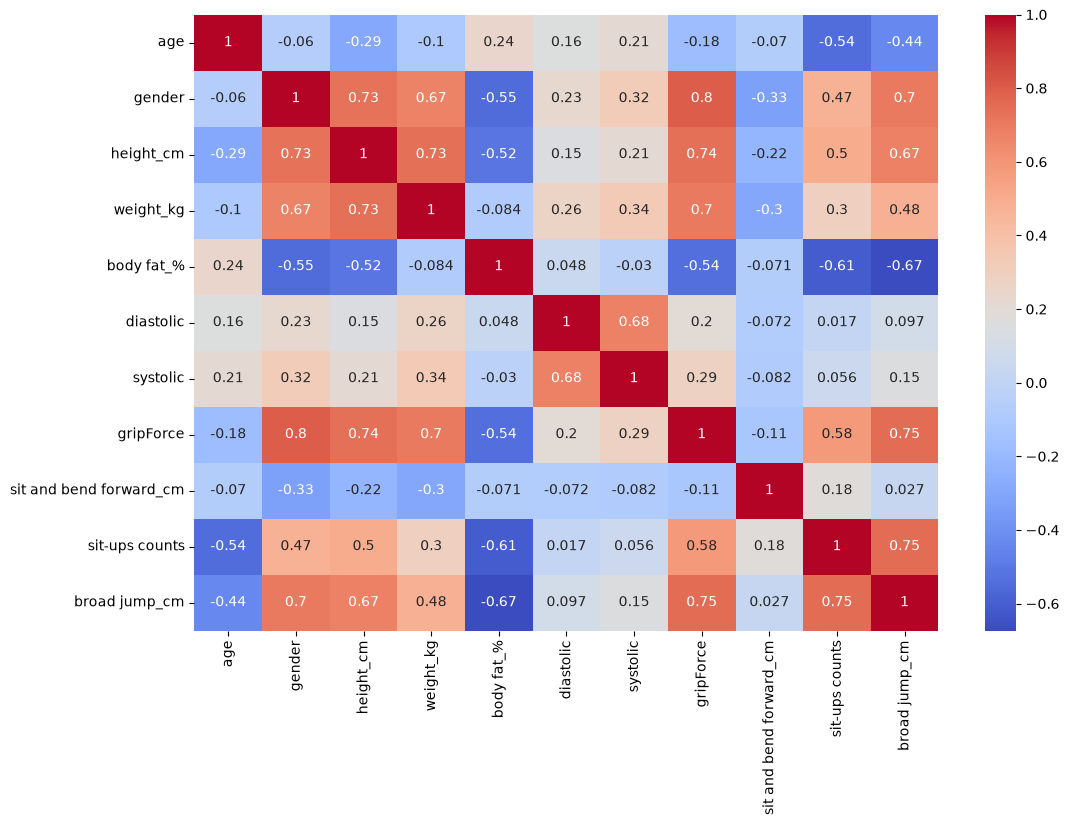

In [31]:
temp = df1.copy()

temp['gender'] = temp['gender'].map({'M':1,'F':0})

corr = temp.corr(numeric_only=True)

plt.figure(figsize=(12,8))
sns.heatmap(corr,annot=True,cmap='coolwarm',)
plt.show()

In [ ]:
#Removing Outliers using IQR method
def remove_outliers_iqr(data, columns):
    data = data.copy()

    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5*IQR
        upper = Q3 + 1.5*IQR

        data = data[(data[col] >= lower) & (data[col] <= upper)]

    return data

num_cols = df1.select_dtypes(include=np.number).columns
df1 = remove_outliers_iqr(df1, num_cols)

print(df1.shape)

(12634, 12)


In [33]:
ohe = OneHotEncoder(drop='first', sparse_output=False)

gender_ohe = ohe.fit_transform(df1[['gender']])

gender_ohe = pd.DataFrame(
    gender_ohe,
    columns=ohe.get_feature_names_out(['gender']),
    index=df1.index
)

df1 = pd.concat(
    [df1.drop('gender', axis=1), gender_ohe],
    axis=1
)

le = LabelEncoder()

df1['class'] = le.fit_transform(df1['class'])

df1.head()

,age,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class,gender_M
0,27.0,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,2,1.0
1,25.0,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,0,1.0
2,31.0,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,2,1.0
3,32.0,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,1,1.0
4,28.0,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,1,1.0


In [34]:
# Feature and target selection
X = df1.drop(columns=['class']).copy()
y = df1['class'].copy()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 10107
Testing samples: 2527


In [35]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [43]:
lr = LogisticRegression(max_iter=2000,random_state=42)
lr.fit(X_train_scaled, y_train)
y_lr_pred = lr.predict(X_test_scaled)

In [37]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,)
rf.fit(X_train, y_train)
y_rf_pred = rf.predict(X_test)


In [38]:
#Comparing model performance
results = []

for name, predictions in [
    ("Logistic Regression", y_lr_pred),
    ("Random Forest", y_rf_pred)]:

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1 Score": f1_score(y_test, predictions, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1 Score", ascending=False).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.7333,0.7439,0.7364,0.7371
1,Logistic Regression,0.5987,0.6021,0.6040,0.6024


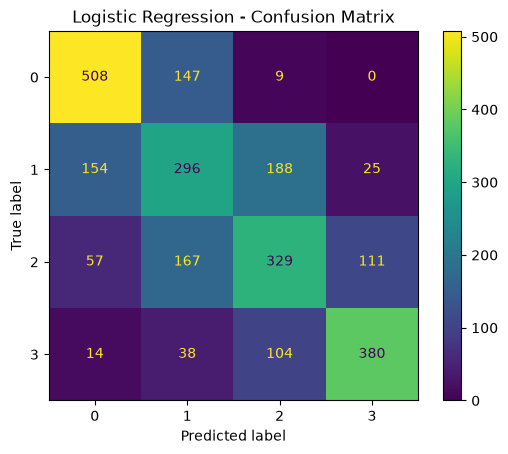

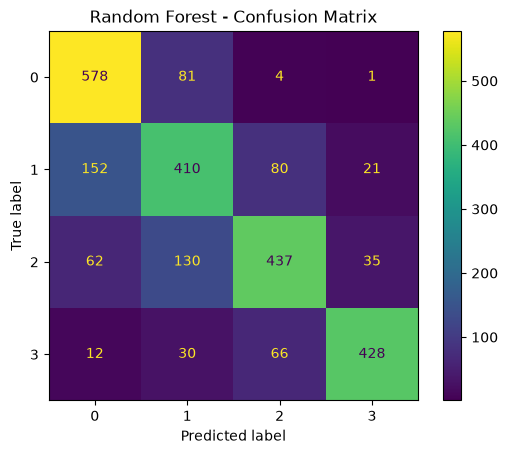

In [39]:
ConfusionMatrixDisplay.from_predictions(y_test, y_lr_pred)
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, y_rf_pred)
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [40]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

display(importance)

,Feature,Importance
0,sit and bend forward_cm,0.241669
1,sit-ups counts,0.130565
2,body fat_%,0.098600
3,age,0.092828
4,weight_kg,0.088828
5,gripForce,0.084533
6,broad jump_cm,0.077972
7,height_cm,0.066700
8,systolic,0.054514
9,diastolic,0.050557


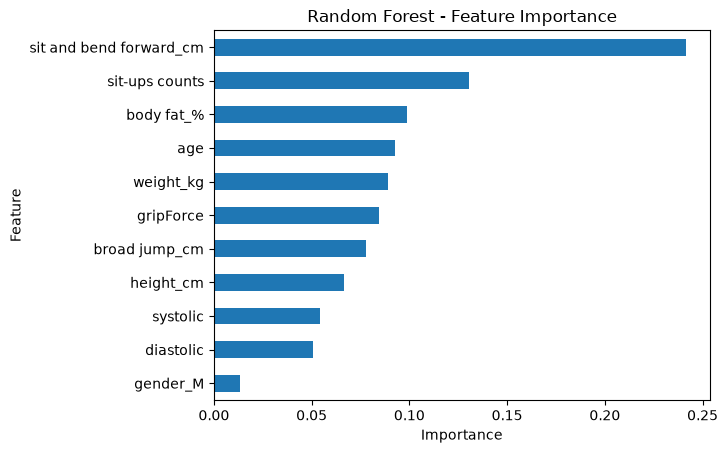

In [41]:
importance.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()

In [42]:
best_model = results_df.iloc[0]

print("FITNESS DATA CLASSIFICATION - MODEL COMPARISON")
print("------------------------------------------------")

print("Dataset records:", len(df1))
print("Number of input features:", X.shape[1])
print("Number of categories:", y.nunique())

print("\nBest model by Macro F1 Score:")
print(best_model["Model"])

print("Accuracy:", round(best_model["Accuracy"], 4))
print("Macro F1 Score:", round(best_model["F1 Score"], 4))

print("\nModel evaluation completed.")

FITNESS DATA CLASSIFICATION - MODEL COMPARISON
------------------------------------------------
Dataset records: 12634
Number of input features: 11
Number of categories: 4

Best model by Macro F1 Score:
Random Forest
Accuracy: 0.7333
Macro F1 Score: 0.7371

Model evaluation completed.


### Conclusion and Key Findings

##### Two classification models, Logistic Regression and Random Forest, were trained and evaluated using accuracy, precision, recall, and F1 score.

##### **Model Comparison:** Random Forest outperformed Logistic Regression, achieving an accuracy of 73.33% and an F1 score of 73.71%, compared to 59.87% accuracy and 60.24% F1 score for Logistic Regression.

##### **Feature Importance:** The three most important features identified by Random Forest were sit and bend forward_cm, sit-ups counts, and body fat_%. These features contributed most to the model's predictions according to its feature importance scores.

##### **Model Evaluation:** Confusion matrices were used to examine correct predictions and identify classes that the models frequently misclassified.

##### **Overall Finding:** Random Forest was the better-performing model on the test dataset. Further hyperparameter tuning and evaluation may help improve its performance.

